In [1]:
import pandas as pd       # tables (DataFrames)
import numpy as np        # numbers and math
from pathlib import Path  # file paths

# show more columns when we print a table
pd.set_option("display.max_columns", 60)

In [2]:
raw_folder = Path("../data/raw")
csv_files = sorted(raw_folder.glob("*.csv"))   # sorted = alphabetical order


In [3]:
city_data = {}   # empty dictionary: city name -> table

for file in csv_files:
    city_name = file.stem          # file name without ".csv", e.g. "Mumbai"
    table = pd.read_csv(file)      # read the CSV into a DataFrame
    table["City"] = city_name      # new column with the city name
    city_data[city_name] = table   # store it in the dictionary

    print(city_name, "->", table.shape)

Bangalore -> (6207, 41)
Chennai -> (5014, 41)
Delhi -> (4998, 41)
Hyderabad -> (2518, 41)
Kolkata -> (6507, 41)
Mumbai -> (7719, 41)


# EDA

In [4]:
city_data["Mumbai"].head()

,Price,Area,Location,No. of Bedrooms,Resale,MaintenanceStaff,Gymnasium,SwimmingPool,LandscapedGardens,JoggingTrack,RainWaterHarvesting,IndoorGames,ShoppingMall,Intercom,SportsFacility,ATM,ClubHouse,School,24X7Security,PowerBackup,CarParking,StaffQuarter,Cafeteria,MultipurposeRoom,Hospital,WashingMachine,Gasconnection,AC,Wifi,Children'splayarea,LiftAvailable,BED,VaastuCompliant,Microwave,GolfCourse,TV,DiningTable,Sofa,Wardrobe,Refrigerator,City
0,4850000,720,Kharghar,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,Mumbai
1,4500000,600,Kharghar,1,1,1,1,1,0,1,1,0,0,0,0,0,1,0,1,1,1,1,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,Mumbai
2,6700000,650,Kharghar,1,1,1,1,1,0,1,1,0,0,1,0,0,1,0,1,1,1,1,0,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,0,Mumbai
3,4500000,650,Kharghar,1,1,1,0,0,1,0,1,0,0,1,0,0,0,0,1,1,1,1,0,0,0,0,0,1,1,0,1,1,1,0,0,0,0,0,1,0,Mumbai
4,5000000,665,Kharghar,1,1,1,0,0,1,0,1,0,0,1,0,0,0,0,1,1,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,Mumbai


**Check column names match across cities**

In [5]:
base_columns = list(city_data["Bangalore"].columns)   # Bangalore's column names

for city_name, table in city_data.items():
    same = list(table.columns) == base_columns         # True if identical, same order
    print(city_name, "-> same columns as Bangalore:", same)

Bangalore -> same columns as Bangalore: True
Chennai -> same columns as Bangalore: True
Delhi -> same columns as Bangalore: True
Hyderabad -> same columns as Bangalore: True
Kolkata -> same columns as Bangalore: True
Mumbai -> same columns as Bangalore: True


**Merge into one table**

In [6]:
df = pd.concat(city_data.values(), ignore_index=True)

print("Combined shape:", df.shape)
print(df["City"].value_counts())    # rows per city

Combined shape: (32963, 41)
City
Mumbai       7719
Kolkata      6507
Bangalore    6207
Chennai      5014
Delhi        4998
Hyderabad    2518
Name: count, dtype: int64


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32963 entries, 0 to 32962
Data columns (total 41 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Price                32963 non-null  int64
 1   Area                 32963 non-null  int64
 2   Location             32963 non-null  str  
 3   No. of Bedrooms      32963 non-null  int64
 4   Resale               32963 non-null  int64
 5   MaintenanceStaff     32963 non-null  int64
 6   Gymnasium            32963 non-null  int64
 7   SwimmingPool         32963 non-null  int64
 8   LandscapedGardens    32963 non-null  int64
 9   JoggingTrack         32963 non-null  int64
 10  RainWaterHarvesting  32963 non-null  int64
 11  IndoorGames          32963 non-null  int64
 12  ShoppingMall         32963 non-null  int64
 13  Intercom             32963 non-null  int64
 14  SportsFacility       32963 non-null  int64
 15  ATM                  32963 non-null  int64
 16  ClubHouse            32963 non-nu

**Missing values**

In [8]:
missing_percent = df.isna().mean() * 100
missing_percent = missing_percent.sort_values(ascending=False)

print(missing_percent.round(1).head(15))

Price                  0.0
Area                   0.0
Location               0.0
No. of Bedrooms        0.0
Resale                 0.0
MaintenanceStaff       0.0
Gymnasium              0.0
SwimmingPool           0.0
LandscapedGardens      0.0
JoggingTrack           0.0
RainWaterHarvesting    0.0
IndoorGames            0.0
ShoppingMall           0.0
Intercom               0.0
SportsFacility         0.0
dtype: float64


In [9]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 3828


**search for bathroom column**

In [10]:
found_bath_columns = []

for column_name in df.columns:
    name_in_lowercase = column_name.lower()
    if "bath" in name_in_lowercase or "toilet" in name_in_lowercase:
        found_bath_columns.append(column_name)

print("Bathroom-related columns:", found_bath_columns)

Bathroom-related columns: []


**Values inside the amenity columns**

In [11]:
main_columns = ["Price", "Area", "Location", "No. of Bedrooms", "City"]

for column_name in df.columns:
    if column_name not in main_columns:
        unique_values = sorted(df[column_name].unique())
        print(column_name, "->", unique_values)

Resale -> [np.int64(0), np.int64(1)]
MaintenanceStaff -> [np.int64(0), np.int64(1), np.int64(9)]
Gymnasium -> [np.int64(0), np.int64(1), np.int64(9)]
SwimmingPool -> [np.int64(0), np.int64(1), np.int64(9)]
LandscapedGardens -> [np.int64(0), np.int64(1), np.int64(9)]
JoggingTrack -> [np.int64(0), np.int64(1), np.int64(9)]
RainWaterHarvesting -> [np.int64(0), np.int64(1), np.int64(9)]
IndoorGames -> [np.int64(0), np.int64(1), np.int64(9)]
ShoppingMall -> [np.int64(0), np.int64(1), np.int64(9)]
Intercom -> [np.int64(0), np.int64(1), np.int64(9)]
SportsFacility -> [np.int64(0), np.int64(1), np.int64(9)]
ATM -> [np.int64(0), np.int64(1), np.int64(9)]
ClubHouse -> [np.int64(0), np.int64(1), np.int64(9)]
School -> [np.int64(0), np.int64(1), np.int64(9)]
24X7Security -> [np.int64(0), np.int64(1), np.int64(9)]
PowerBackup -> [np.int64(0), np.int64(1), np.int64(9)]
CarParking -> [np.int64(0), np.int64(1), np.int64(9)]
StaffQuarter -> [np.int64(0), np.int64(1), np.int64(9)]
Cafeteria -> [np.int64

In [12]:
count_of_nines = {}   # empty dictionary: column name -> number of 9s

for column_name in df.columns:
    if column_name not in main_columns:
        count_of_nines[column_name] = (df[column_name] == 9).sum()

nines_series = pd.Series(count_of_nines).sort_values(ascending=False)
print(nines_series.head(10))
print("Rows where Gymnasium is 9:", round((df["Gymnasium"] == 9).mean() * 100, 1), "%")

MaintenanceStaff       22870
Gymnasium              22870
SwimmingPool           22870
LandscapedGardens      22870
Hospital               22870
JoggingTrack           22870
RainWaterHarvesting    22870
IndoorGames            22870
ShoppingMall           22870
Intercom               22870
dtype: int64
Rows where Gymnasium is 9: 69.4 %


**Price and Area summary**

In [13]:
df[["Price", "Area", "No. of Bedrooms"]].describe()

,Price,Area,No. of Bedrooms
count,3.296300e+04,32963.000000,32963.000000
mean,1.168672e+07,1293.362194,2.411765
std,2.307368e+07,763.703754,0.812800
min,2.000000e+06,200.000000,1.000000
25%,4.071500e+06,853.000000,2.000000
50%,6.711000e+06,1125.000000,2.000000
75%,1.200000e+07,1500.000000,3.000000
max,8.546000e+08,16000.000000,9.000000


**Price per square foot by city**

In [14]:
df["Price_Per_SqFt"] = df["Price"] / df["Area"]   # temporary check column

print(df.groupby("City")["Price_Per_SqFt"].median().round(0).sort_values())

City
Kolkata       4342.0
Hyderabad     5000.0
Bangalore     5372.0
Chennai       5383.0
Delhi         6000.0
Mumbai       10410.0
Name: Price_Per_SqFt, dtype: float64


**Are the 9s all-or-nothing per row?**

In [15]:
# amenity columns = everything except the main columns, Resale and our temp column
amenity_columns = []
for column_name in df.columns:
    if column_name not in main_columns + ["Resale", "Price_Per_SqFt"]:
        amenity_columns.append(column_name)

print("Number of amenity columns:", len(amenity_columns))

nines_per_row = (df[amenity_columns] == 9).sum(axis=1)   # count of 9s in each row

print("Rows with every amenity = 9:", (nines_per_row == len(amenity_columns)).sum())
print("Rows with some (not all) 9s:", ((nines_per_row > 0) & (nines_per_row < len(amenity_columns))).sum())
print("Rows with no 9s at all     :", (nines_per_row == 0).sum())

Number of amenity columns: 35
Rows with every amenity = 9: 22870
Rows with some (not all) 9s: 0
Rows with no 9s at all     : 10093


**Share of rows without amenity info, by city**

In [16]:
rows_without_info = nines_per_row > 0     # True where amenity info is missing
print((rows_without_info.groupby(df["City"]).mean() * 100).round(1))

City
Bangalore    68.6
Chennai      55.5
Delhi        59.9
Hyderabad     3.3
Kolkata      98.8
Mumbai       81.9
dtype: float64


**Duplicates by city**

In [17]:
duplicate_flags = df.duplicated()
print(duplicate_flags.groupby(df["City"]).sum())
print("Duplicates among rows WITH amenity info   :", (duplicate_flags & ~rows_without_info).sum())
print("Duplicates among rows WITHOUT amenity info:", (duplicate_flags & rows_without_info).sum())

City
Bangalore    686
Chennai      707
Delhi        889
Hyderabad    520
Kolkata      232
Mumbai       794
dtype: int64
Duplicates among rows WITH amenity info   : 1867
Duplicates among rows WITHOUT amenity info: 1961


**Small-area and low-price-per-sqft counts**

In [18]:
print("Area < 300 sq ft          :", (df["Area"] < 300).sum())
print("Price per sq ft < 1500    :", (df["Price_Per_SqFt"] < 1500).sum())
print("Price per sq ft max       :", round(df["Price_Per_SqFt"].max()))

Area < 300 sq ft          : 59
Price per sq ft < 1500    : 510
Price per sq ft max       : 1076444


# VISUALISATION

In [19]:
import matplotlib.pyplot as plt   # basic plotting
import seaborn as sns             # nicer, simpler statistical plots

sns.set_theme(style="whitegrid")  # light grid behind charts

**droping duplicates and making sperate df for eda**

In [20]:
eda_df = df.copy()

# 1 = listing has real amenity info, 0 = all amenities were 9
eda_df["Amenity_Info_Available"] = (nines_per_row == 0).astype(int)

# replace 9 with NaN (missing) in the 35 amenity columns
eda_df[amenity_columns] = eda_df[amenity_columns].replace(9, np.nan)

# drop exact duplicate rows
rows_before = len(eda_df)
eda_df = eda_df.drop_duplicates().reset_index(drop=True)
print("Rows before:", rows_before, "| after:", len(eda_df))

Rows before: 32963 | after: 29135


In [21]:
print(eda_df.shape)
print(eda_df["Amenity_Info_Available"].value_counts())
print(eda_df["Gymnasium"].value_counts(dropna=False))

(29135, 43)
Amenity_Info_Available
0    20909
1     8226
Name: count, dtype: int64
Gymnasium
NaN    20909
1.0     4360
0.0     3866
Name: count, dtype: int64


# Univariate EDA

**Price distribution, raw vs log**

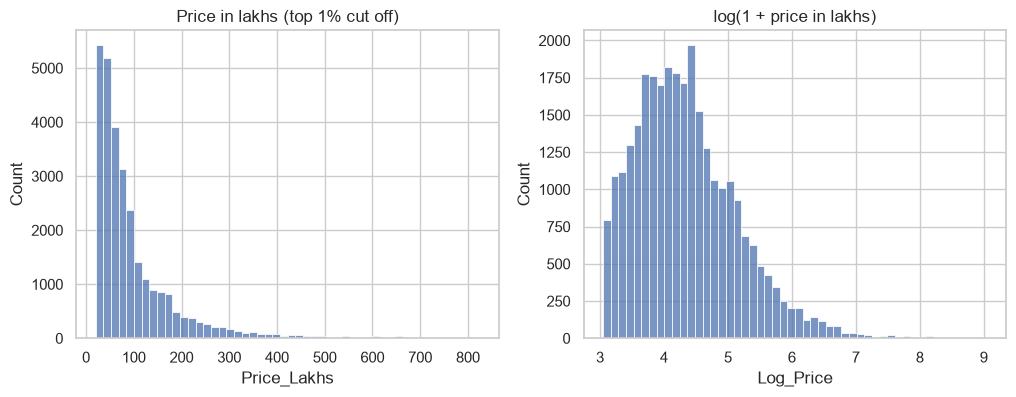

Skewness raw: 13.92
Skewness log: 0.94


In [22]:
eda_df["Price_Lakhs"] = eda_df["Price"] / 100000          # rupees -> lakhs
eda_df["Log_Price"] = np.log1p(eda_df["Price_Lakhs"])     # log(1 + price)

price_cap = eda_df["Price_Lakhs"].quantile(0.99)   # value below which 99% of prices fall

fig, axes = plt.subplots(1, 2, figsize=(12, 4))    # two charts side by side

cheap_enough = eda_df[eda_df["Price_Lakhs"] <= price_cap]
sns.histplot(cheap_enough["Price_Lakhs"], bins=50, ax=axes[0])
axes[0].set_title("Price in lakhs (top 1% cut off)")

sns.histplot(eda_df["Log_Price"], bins=50, ax=axes[1])
axes[1].set_title("log(1 + price in lakhs)")
plt.show()

print("Skewness raw:", round(eda_df["Price_Lakhs"].skew(), 2))
print("Skewness log:", round(eda_df["Log_Price"].skew(), 2))

**Area distribution**

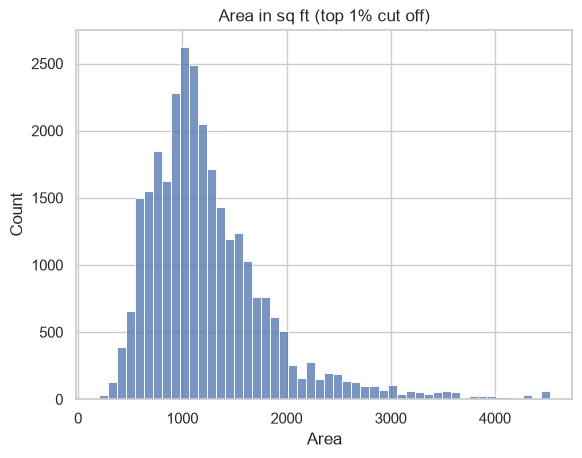

99th percentile of Area: 4527.0
Skewness: 3.55


In [23]:
area_cap = eda_df["Area"].quantile(0.99)
normal_areas = eda_df[eda_df["Area"] <= area_cap]

sns.histplot(normal_areas["Area"], bins=50)
plt.title("Area in sq ft (top 1% cut off)")
plt.show()

print("99th percentile of Area:", area_cap)
print("Skewness:", round(eda_df["Area"].skew(), 2))

**Bedrooms, City and Resale counts**

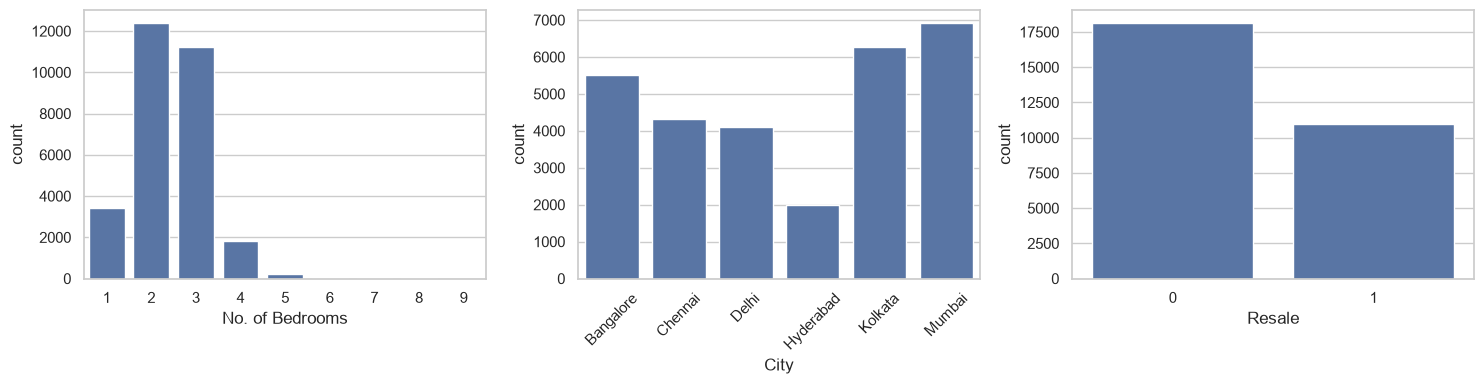

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.countplot(data=eda_df, x="No. of Bedrooms", ax=axes[0])
sns.countplot(data=eda_df, x="City", ax=axes[1])
axes[1].tick_params(axis="x", rotation=45)      # tilt city names so they fit
sns.countplot(data=eda_df, x="Resale", ax=axes[2])

plt.tight_layout()
plt.show()

**Locality (high-cardinality column)**

In [25]:
locality_counts = eda_df["Location"].value_counts()

print("Different localities:", len(locality_counts))
print("Localities with fewer than 5 listings:", (locality_counts < 5).sum())

rare_listings = locality_counts[locality_counts < 5].sum()
print("Share of all rows in those rare localities:",
      round(rare_listings / len(eda_df) * 100, 1), "%")

print(locality_counts.head(10))

Different localities: 1776
Localities with fewer than 5 listings: 1061
Share of all rows in those rare localities: 6.1 %
Location
New Town          687
Kharghar          566
Thane West        503
Mira Road East    453
Rajarhat          403
Uttam Nagar       375
Tangra            359
Noida             342
Ulwe              332
Dwarka Mor        302
Name: count, dtype: int64


# Bivariate EDA

**Price by city**

City
Kolkata      49.2
Chennai      58.5
Bangalore    73.0
Delhi        78.0
Hyderabad    78.7
Mumbai       95.0
Name: Price_Lakhs, dtype: float64


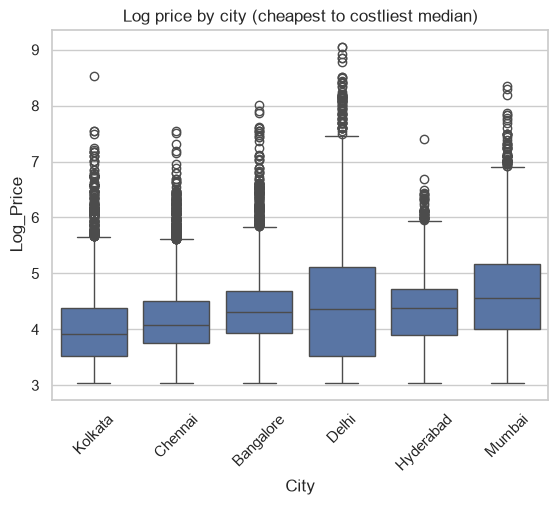

In [26]:
city_median = eda_df.groupby("City")["Price_Lakhs"].median().sort_values()
print(city_median.round(1))

sns.boxplot(data=eda_df, x="City", y="Log_Price", order=city_median.index)
plt.title("Log price by city (cheapest to costliest median)")
plt.xticks(rotation=45)
plt.show()

**Price by bedrooms**

                 count  median
No. of Bedrooms               
1                 3436    60.0
2                12399    59.0
3                11217    80.0
4                 1834   133.5
5                  202   146.5
6                   31   134.0
7                    8   157.5
8                    7   500.0
9                    1    24.0


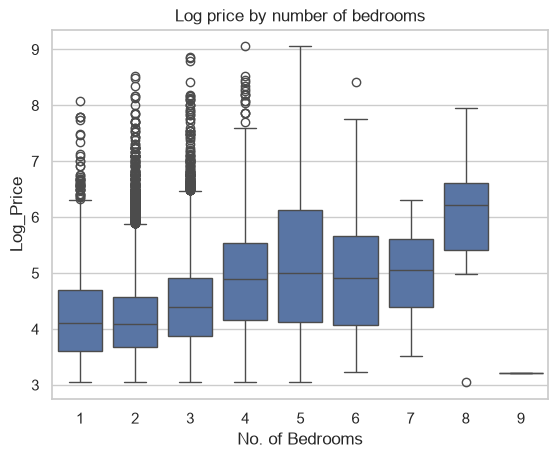

In [27]:
print(eda_df.groupby("No. of Bedrooms")["Price_Lakhs"].agg(["count", "median"]).round(1))

sns.boxplot(data=eda_df, x="No. of Bedrooms", y="Log_Price")
plt.title("Log price by number of bedrooms")
plt.show()

**Price vs Area**

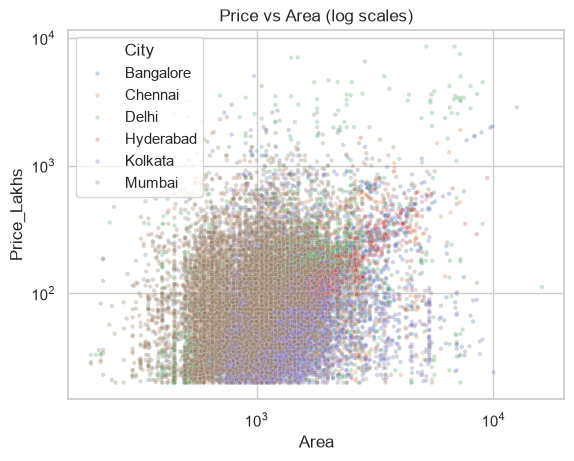

Correlation, raw Area vs raw Price: 0.27
Correlation, log Area vs log Price: 0.32


In [28]:
sns.scatterplot(data=eda_df, x="Area", y="Price_Lakhs", hue="City", alpha=0.3, s=10)
plt.xscale("log")
plt.yscale("log")
plt.title("Price vs Area (log scales)")
plt.show()

log_area = np.log(eda_df["Area"])
print("Correlation, raw Area vs raw Price:", round(eda_df["Area"].corr(eda_df["Price_Lakhs"]), 2))
print("Correlation, log Area vs log Price:", round(log_area.corr(eda_df["Log_Price"]), 2))

**Price per sq ft by city**

City
Kolkata       4314.0
Hyderabad     5111.0
Bangalore     5345.0
Chennai       5419.0
Delhi         7002.0
Mumbai       10614.0
Name: Price_Per_SqFt, dtype: float64


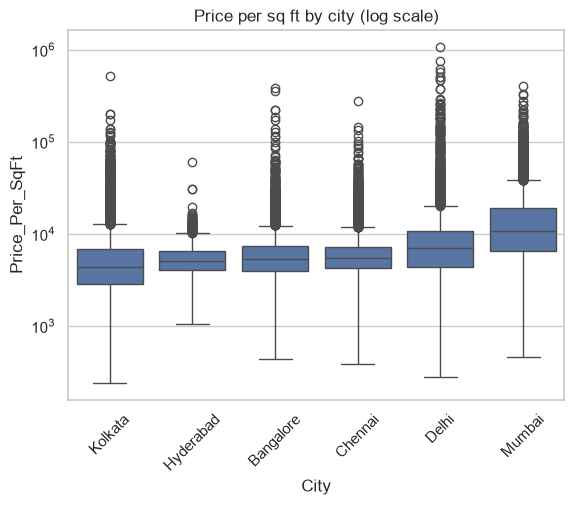

In [29]:
psf_median = eda_df.groupby("City")["Price_Per_SqFt"].median().sort_values()
print(psf_median.round(0))

sns.boxplot(data=eda_df, x="City", y="Price_Per_SqFt", order=psf_median.index)
plt.yscale("log")
plt.xticks(rotation=45)
plt.title("Price per sq ft by city (log scale)")
plt.show()

**Testing what Resale means**

In [30]:
resale_table = eda_df.groupby(["City", "Resale"])["Price_Per_SqFt"].median().unstack()
print(resale_table.round(0))

Resale           0        1
City                       
Bangalore   5404.0   4356.0
Chennai     5402.0   5925.0
Delhi       5125.0   8056.0
Hyderabad   5000.0   5680.0
Kolkata     4326.0   4294.0
Mumbai     11628.0  10098.0


**Does having amenity info relate to price?**

In [31]:
info_vs_price = eda_df.groupby(["City", "Amenity_Info_Available"])["Price_Per_SqFt"].median()
print(info_vs_price.unstack().round(0))

Amenity_Info_Available        0       1
City                                   
Bangalore                5444.0  5235.0
Chennai                  5459.0  5391.0
Delhi                    6538.0  7558.0
Hyderabad                4878.0  5115.0
Kolkata                  4324.0  4000.0
Mumbai                  10984.0  9665.0


**Amenity count vs price**

In [32]:
info_rows = eda_df[eda_df["Amenity_Info_Available"] == 1].copy()
info_rows["Amenity_Count"] = info_rows[amenity_columns].sum(axis=1)
info_rows["Log_PSF"] = np.log(info_rows["Price_Per_SqFt"])

print(info_rows["Amenity_Count"].describe().round(1))

for city_name in info_rows["City"].unique():
    city_rows = info_rows[info_rows["City"] == city_name]
    if len(city_rows) >= 100:
        corr = city_rows["Amenity_Count"].corr(city_rows["Log_PSF"])
        print(city_name, "|", len(city_rows), "rows | correlation:", round(corr, 2))

count    8226.0
mean        8.4
std         6.9
min         0.0
25%         2.0
50%         7.0
75%        14.0
max        35.0
Name: Amenity_Count, dtype: float64
Bangalore | 1617 rows | correlation: 0.32
Chennai | 1768 rows | correlation: 0.24
Delhi | 1716 rows | correlation: 0.41
Hyderabad | 1914 rows | correlation: 0.38
Mumbai | 1156 rows | correlation: 0.09


**Same locality name in different cities?**

In [33]:
cities_per_locality = eda_df.groupby("Location")["City"].nunique()
shared_localities = cities_per_locality[cities_per_locality > 1]

print("Localities appearing in more than one city:", len(shared_localities))
print(shared_localities.head(10))

Localities appearing in more than one city: 12
Location
Ashok Nagar       4
Moti Nagar        2
Rajendra Nagar    2
Rajpur            2
Saket             2
Sector 10         2
Shakti Nagar      2
Shastri Nagar     2
Tilak Nagar       2
Vasant Vihar      2
Name: City, dtype: int64


**Area vs price inside one locality**

Rows: 566


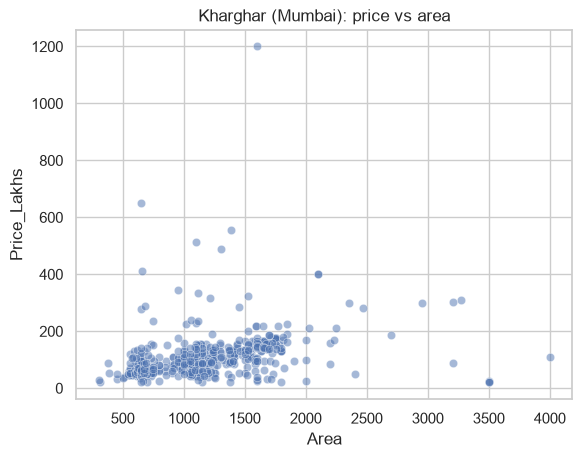

Correlation: 0.34


In [34]:
one_locality = eda_df[(eda_df["City"] == "Mumbai") & (eda_df["Location"] == "Kharghar")]
print("Rows:", len(one_locality))

sns.scatterplot(data=one_locality, x="Area", y="Price_Lakhs", alpha=0.5)
plt.title("Kharghar (Mumbai): price vs area")
plt.show()

print("Correlation:", round(one_locality["Area"].corr(one_locality["Price_Lakhs"]), 2))

**Area vs price inside each city**

In [35]:
for city_name in eda_df["City"].unique():
    city_rows = eda_df[eda_df["City"] == city_name]
    corr = np.log(city_rows["Area"]).corr(city_rows["Log_Price"])
    print(city_name, "| log Area vs log Price correlation:", round(corr, 2))

Bangalore | log Area vs log Price correlation: 0.46
Chennai | log Area vs log Price correlation: 0.47
Delhi | log Area vs log Price correlation: 0.56
Hyderabad | log Area vs log Price correlation: 0.86
Kolkata | log Area vs log Price correlation: 0.12
Mumbai | log Area vs log Price correlation: 0.31


**removing suspicious rows and checking corelation**

In [36]:
sensible = eda_df[(eda_df["Price_Per_SqFt"] >= 1500) & (eda_df["Price_Per_SqFt"] <= 50000)]
print("Rows kept:", len(sensible), "of", len(eda_df))

log_area_sensible = np.log(sensible["Area"])
print("Correlation after filtering:", round(log_area_sensible.corr(sensible["Log_Price"]), 2))

Rows kept: 28072 of 29135
Correlation after filtering: 0.44


# Multivariate EDA

**the Locality key**

In [37]:
eda_df["Locality"] = eda_df["City"] + " | " + eda_df["Location"]

print("Old Location count:", eda_df["Location"].nunique())
print("New Locality count:", eda_df["Locality"].nunique())
print(eda_df["Locality"].head())

Old Location count: 1776
New Locality count: 1790
0                   Bangalore | JP Nagar Phase 1
1         Bangalore | Dasarahalli on Tumkur Road
2    Bangalore | Kannur on Thanisandra Main Road
3                       Bangalore | Doddanekundi
4                            Bangalore | Kengeri
Name: Locality, dtype: str


**Correlation heatmap**

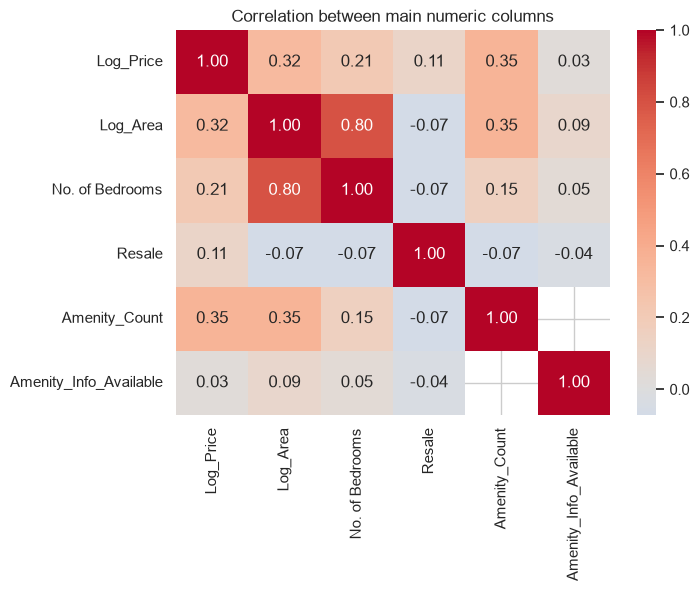

In [38]:
eda_df["Log_Area"] = np.log(eda_df["Area"])
eda_df["Amenity_Count"] = eda_df[amenity_columns].sum(axis=1, min_count=1)

columns_for_heatmap = ["Log_Price", "Log_Area", "No. of Bedrooms", "Resale",
                       "Amenity_Count", "Amenity_Info_Available"]
correlation_matrix = eda_df[columns_for_heatmap].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between main numeric columns")
plt.show()

**Do different cities have different drivers?**


In [39]:
features_to_check = ["Log_Area", "No. of Bedrooms", "Resale", "Amenity_Count"]
city_correlations = {}

for city_name in sorted(eda_df["City"].unique()):
    city_rows = eda_df[eda_df["City"] == city_name]
    correlations = city_rows[features_to_check].corrwith(city_rows["Log_Price"])
    city_correlations[city_name] = correlations

city_corr_table = pd.DataFrame(city_correlations).T   # .T flips rows and columns
print(city_corr_table.round(2))

           Log_Area  No. of Bedrooms  Resale  Amenity_Count
Bangalore      0.46             0.33   -0.04           0.33
Chennai        0.47             0.37    0.10           0.39
Delhi          0.56             0.33    0.21           0.52
Hyderabad      0.86             0.69    0.17           0.41
Kolkata        0.12             0.08    0.03           0.39
Mumbai         0.31             0.32   -0.05           0.26


**Price vs Area, one chart per city**

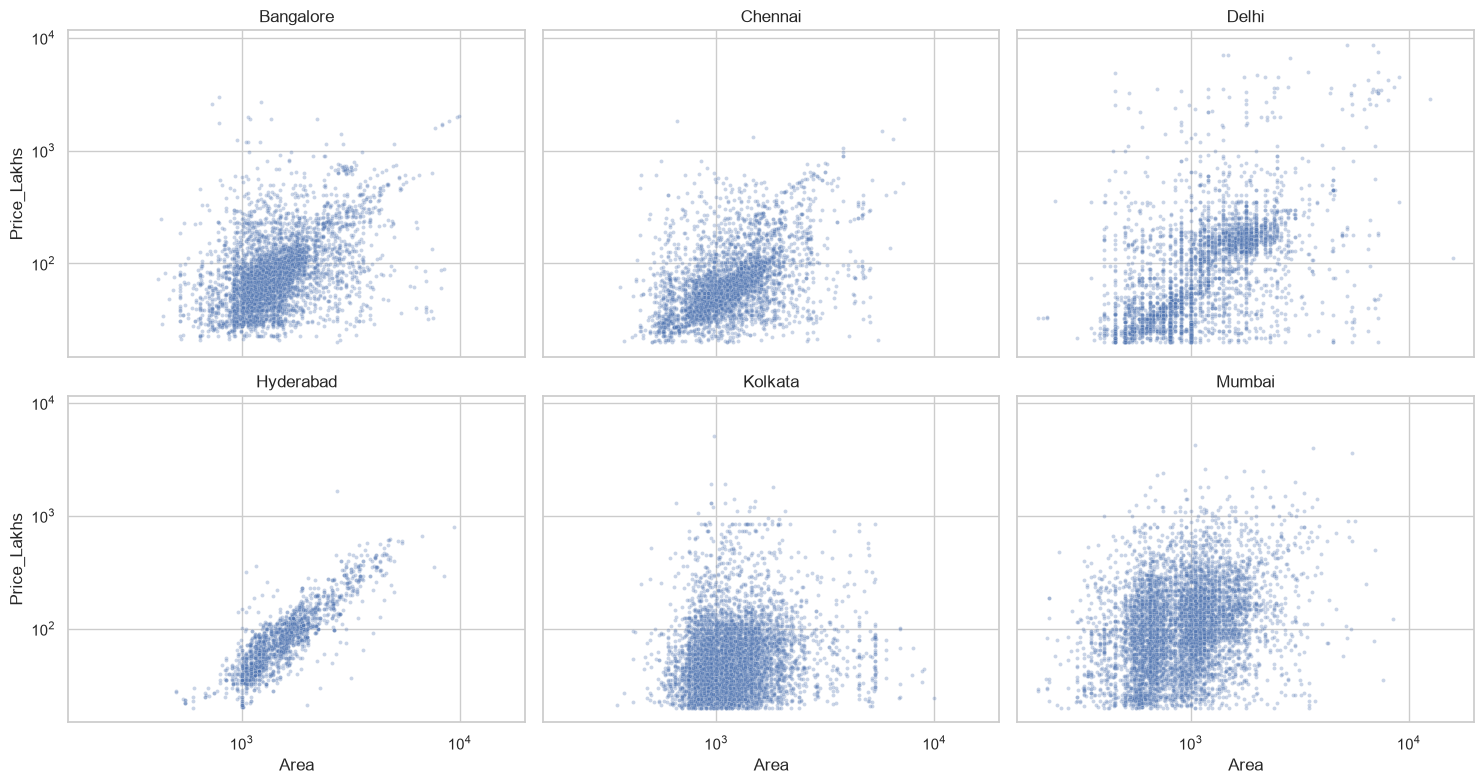

In [40]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
axes = axes.flatten()    # turn the 2x3 grid into a simple list of 6 charts

city_names = sorted(eda_df["City"].unique())

for position in range(len(city_names)):
    city_name = city_names[position]
    city_rows = eda_df[eda_df["City"] == city_name]
    sns.scatterplot(data=city_rows, x="Area", y="Price_Lakhs",
                    alpha=0.3, s=8, ax=axes[position])
    axes[position].set_xscale("log")
    axes[position].set_yscale("log")
    axes[position].set_title(city_name)

plt.tight_layout()
plt.show()

**Price and Area by City and BHK**

In [41]:
bhk_1_to_4 = eda_df[eda_df["No. of Bedrooms"] <= 4]

price_table = bhk_1_to_4.groupby(["City", "No. of Bedrooms"])["Price_Lakhs"].median().unstack()
area_table = bhk_1_to_4.groupby(["City", "No. of Bedrooms"])["Area"].median().unstack()

print("Median price in lakhs:")
print(price_table.round(0))
print()
print("Median area in sq ft:")
print(area_table.round(0))

Median price in lakhs:
No. of Bedrooms     1      2      3      4
City                                      
Bangalore        55.0   61.0   83.0  144.0
Chennai          36.0   52.0   75.0  110.0
Delhi            50.0   36.0  120.0  175.0
Hyderabad        33.0   49.0   98.0  270.0
Kolkata          49.0   46.0   52.0   59.0
Mumbai           68.0  100.0  148.0  231.0

Median area in sq ft:
No. of Bedrooms      1       2       3       4
City                                          
Bangalore        705.0  1130.0  1565.0  3165.0
Chennai          584.0   932.0  1468.0  2655.0
Delhi            520.0   800.0  1400.0  2200.0
Hyderabad        995.0  1150.0  1704.0  3279.0
Kolkata          850.0   908.0  1316.0  2300.0
Mumbai           602.0   990.0  1450.0  2415.0


**: How much does location vary inside a city?**

Localities with 30+ listings: 233
Share of all rows they cover: 72.7 %


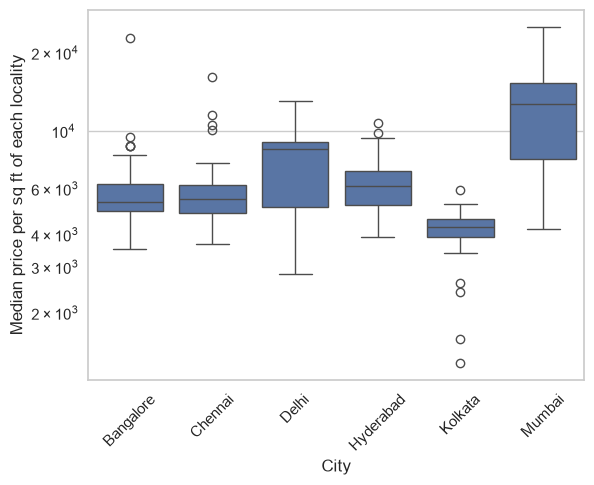

In [42]:
locality_stats = eda_df.groupby(["City", "Locality"])["Price_Per_SqFt"].agg(["count", "median"]).reset_index()
big_localities = locality_stats[locality_stats["count"] >= 30]

print("Localities with 30+ listings:", len(big_localities))
rows_covered = big_localities["count"].sum()
print("Share of all rows they cover:", round(rows_covered / len(eda_df) * 100, 1), "%")

sns.boxplot(data=big_localities, x="City", y="median")
plt.yscale("log")
plt.ylabel("Median price per sq ft of each locality")
plt.xticks(rotation=45)
plt.show()

# Data Preprocessing

**Repeated values (possible placeholders)**

In [43]:
for city_name in sorted(eda_df["City"].unique()):
    city_rows = eda_df[eda_df["City"] == city_name]

    top_areas = city_rows["Area"].value_counts().head(3)
    top_prices = city_rows["Price"].value_counts().head(3)

    print(city_name, "| rows:", len(city_rows))
    print("  Most common areas (sq ft):", top_areas.to_dict())
    print("  Most common prices (Rs):  ", top_prices.to_dict())

Bangalore | rows: 5521
  Most common areas (sq ft): {1500: 98, 1400: 57, 1200: 50}
  Most common prices (Rs):   {8400000: 72, 3100000: 53, 11000000: 38}
Chennai | rows: 4307
  Most common areas (sq ft): {920: 34, 721: 34, 1200: 34}
  Most common prices (Rs):   {4000000: 32, 11000000: 28, 6500000: 27}
Delhi | rows: 4109
  Most common areas (sq ft): {800: 280, 1000: 276, 1800: 243}
  Most common prices (Rs):   {2500000: 86, 3500000: 76, 15500000: 75}
Hyderabad | rows: 1998
  Most common areas (sq ft): {1150: 57, 1050: 57, 1100: 52}
  Most common prices (Rs):   {4500000: 35, 3900000: 34, 5500000: 33}
Kolkata | rows: 6275
  Most common areas (sq ft): {800: 134, 750: 93, 1100: 87}
  Most common prices (Rs):   {4000000: 97, 5500000: 95, 4500000: 93}
Mumbai | rows: 6925
  Most common areas (sq ft): {650: 264, 1050: 154, 600: 149}
  Most common prices (Rs):   {8500000: 117, 9000000: 101, 7500000: 99}


**Price per sq ft by BHK, and Delhi’s localities**

In [44]:
psf_by_bhk = bhk_1_to_4.groupby(["City", "No. of Bedrooms"])["Price_Per_SqFt"].median().unstack()
print(psf_by_bhk.round(0))

delhi_rows = eda_df[eda_df["City"] == "Delhi"]
print("\nTop Delhi localities for 1 BHK:")
print(delhi_rows[delhi_rows["No. of Bedrooms"] == 1]["Location"].value_counts().head(5))
print("\nTop Delhi localities for 2 BHK:")
print(delhi_rows[delhi_rows["No. of Bedrooms"] == 2]["Location"].value_counts().head(5))

No. of Bedrooms        1        2       3       4
City                                             
Bangalore         6780.0   5339.0  5314.0  5141.0
Chennai           5993.0   5475.0  5268.0  4729.0
Delhi             9092.0   5333.0  7391.0  8182.0
Hyderabad         4083.0   4362.0  5500.0  8282.0
Kolkata           5585.0   5114.0  3901.0  2357.0
Mumbai           11473.0  10455.0  9836.0  9213.0

Top Delhi localities for 1 BHK:
Location
Vasant Kunj                   36
Sarita Vihar                  31
Jasola Vihar Sector 8 Road    12
Badarpur                      10
Sector 23 Dwarka               9
Name: count, dtype: int64

Top Delhi localities for 2 BHK:
Location
Noida          195
Uttam Nagar    164
Dwarka Mor     130
Vasant Kunj     65
Burari          52
Name: count, dtype: int64


**Where the extremes begin, per city**

In [45]:
percent_points = [0.005, 0.01, 0.05, 0.95, 0.99, 0.995]
psf_percentiles = eda_df.groupby("City")["Price_Per_SqFt"].quantile(percent_points).unstack()
print(psf_percentiles.round(0))

            0.005   0.010   0.050    0.950     0.990     0.995
City                                                          
Bangalore  1012.0  1395.0  2334.0  17351.0   35901.0   50121.0
Chennai    1181.0  1416.0  2374.0  18484.0   37258.0   50673.0
Delhi       701.0  1101.0  2222.0  33333.0  141972.0  217368.0
Hyderabad  2002.0  2200.0  2973.0   9499.0   13339.0   15003.0
Kolkata     683.0   888.0  1600.0  17320.0   55298.0   75798.0
Mumbai     1403.0  1869.0  3101.0  47983.0  100000.0  130834.0


**suspicious rows**

In [46]:
too_cheap = eda_df[eda_df["Price_Per_SqFt"] < 1500]
too_costly = eda_df[eda_df["Price_Per_SqFt"] > 50000]
columns_to_show = ["City", "Location", "No. of Bedrooms", "Area", "Price_Lakhs", "Price_Per_SqFt"]

print("Below Rs 1500 per sq ft:", len(too_cheap))
print(too_cheap["City"].value_counts())
print(too_cheap[columns_to_show].sample(5, random_state=1))

print("\nAbove Rs 50000 per sq ft:", len(too_costly))
print(too_costly["City"].value_counts())
print(too_costly[columns_to_show].sample(5, random_state=1))

Below Rs 1500 per sq ft: 499
City
Kolkata      258
Delhi         77
Bangalore     70
Chennai       51
Mumbai        40
Hyderabad      3
Name: count, dtype: int64
          City              Location  No. of Bedrooms  Area  Price_Lakhs  \
9254   Chennai  Kanathur Reddikuppam                5  5093         30.3   
12448    Delhi              Om Nagar                2  2322         20.0   
19094  Kolkata            Ballygunge                6  7000         25.0   
19551  Kolkata            Ballygunge                6  4640         55.0   
13765    Delhi            Golf Links                6  3375         36.0   

       Price_Per_SqFt  
9254       594.934223  
12448      861.326443  
19094      357.142857  
19551     1185.344828  
13765     1066.666667  

Above Rs 50000 per sq ft: 564
City
Mumbai       308
Delhi        123
Kolkata       80
Bangalore     28
Chennai       24
Hyderabad      1
Name: count, dtype: int64
          City           Location  No. of Bedrooms  Area  Price_Lakhs  \


**Does Resale matter inside the same locality?**

In [47]:
ratios = []   # one ratio per locality

for locality_name in big_localities["Locality"]:
    rows = eda_df[eda_df["Locality"] == locality_name]
    flag_0_rows = rows[rows["Resale"] == 0]
    flag_1_rows = rows[rows["Resale"] == 1]

    if len(flag_0_rows) >= 10 and len(flag_1_rows) >= 10:
        ratio = flag_1_rows["Price_Per_SqFt"].median() / flag_0_rows["Price_Per_SqFt"].median()
        ratios.append(ratio)

ratio_series = pd.Series(ratios)
print("Localities compared:", len(ratio_series))
print("Median ratio (Resale=1 / Resale=0):", round(ratio_series.median(), 2))
print("Localities where Resale=1 costs more:", round((ratio_series > 1).mean() * 100), "%")

Localities compared: 88
Median ratio (Resale=1 / Resale=0): 1.0
Localities where Resale=1 costs more: 51 %


**Choosing the outlier rule**

In [48]:
# 1. typical price per sq ft for each row's own locality
locality_median_psf = eda_df.groupby("Locality")["Price_Per_SqFt"].transform("median")
locality_row_count = eda_df.groupby("Locality")["Price_Per_SqFt"].transform("count")
city_median_psf = eda_df.groupby("City")["Price_Per_SqFt"].transform("median")

# 2. use the locality median if it has 10+ rows, otherwise the city median
typical_psf = np.where(locality_row_count >= 10, locality_median_psf, city_median_psf)

# 3. how many times bigger or smaller is each row than its typical value?
eda_df["Ratio_To_Typical"] = eda_df["Price_Per_SqFt"] / typical_psf

# 4. the two rules (True = row would be removed)
rule_a = (eda_df["Price_Per_SqFt"] < 1500) | (eda_df["Price_Per_SqFt"] > 50000)
rule_b = (eda_df["Ratio_To_Typical"] < 0.25) | (eda_df["Ratio_To_Typical"] > 4)
rule_either = rule_a | rule_b

summary = pd.DataFrame({
    "Rule A (fixed limits)": rule_a.groupby(eda_df["City"]).sum(),
    "Rule B (vs own locality)": rule_b.groupby(eda_df["City"]).sum(),
    "A or B": rule_either.groupby(eda_df["City"]).sum(),
})
summary.loc["TOTAL"] = summary.sum()
print(summary)

print("\nShare of all rows removed (%):")
print((summary.loc["TOTAL"] / len(eda_df) * 100).round(1))

# how sensitive is Rule B to the "4x" choice?
for multiplier in [3, 4, 5]:
    flagged = (eda_df["Ratio_To_Typical"] < 1 / multiplier) | (eda_df["Ratio_To_Typical"] > multiplier)
    print("Rule B with", multiplier, "x ->", flagged.sum(), "rows removed")

           Rule A (fixed limits)  Rule B (vs own locality)  A or B
City                                                              
Bangalore                     98                       230     250
Chennai                       75                       189     198
Delhi                        200                       380     392
Hyderabad                      4                         7       9
Kolkata                      338                       370     590
Mumbai                       348                       648     717
TOTAL                       1063                      1824    2156

Share of all rows removed (%):
Rule A (fixed limits)       3.6
Rule B (vs own locality)    6.3
A or B                      7.4
Name: TOTAL, dtype: float64
Rule B with 3 x -> 3006 rows removed
Rule B with 4 x -> 1824 rows removed
Rule B with 5 x -> 1254 rows removed


In [49]:
columns_to_show = ["City", "Location", "No. of Bedrooms", "Area", "Price_Lakhs",
                   "Price_Per_SqFt", "Ratio_To_Typical"]

only_b = eda_df[rule_b & ~rule_a]    # Rule B removes them, Rule A keeps them
only_a = eda_df[rule_a & ~rule_b]    # Rule A removes them, Rule B keeps them

print("Removed only by Rule B:", len(only_b))
print(only_b[columns_to_show].sample(min(6, len(only_b)), random_state=1).round(1))

print("\nRemoved only by Rule A:", len(only_a))
print(only_a[columns_to_show].sample(min(6, len(only_a)), random_state=1).round(1))

Removed only by Rule B: 1093
            City                                Location  No. of Bedrooms  \
4596   Bangalore                              Chandapura                2   
8031     Chennai                           Thiruvanmiyur                3   
7437     Chennai                             Perumbakkam                2   
24635     Mumbai                                Kharghar                2   
20127    Kolkata  Residential Independent House Jadavpur                2   
12810      Delhi                              Sector 108                3   

       Area  Price_Lakhs  Price_Per_SqFt  Ratio_To_Typical  
4596    785        230.0         29299.4               4.7  
8031   1200         30.1          2510.8               0.2  
7437    855        242.0         28304.1               5.9  
24635  1150         23.0          2000.0               0.2  
20127   850        200.0         23529.4               5.5  
12810  1490        470.0         31543.6               4.5  

Rem

**Junk text inside Location**

In [50]:
keywords = ["house", "residential", "apartment", "villa", "flat", "plot", "floor"]
location_lower = eda_df["Location"].str.lower()

has_any_keyword = pd.Series(False, index=eda_df.index)   # start with all False

for word in keywords:
    has_word = location_lower.str.contains(word)
    print(word, "->", has_word.sum(), "rows")
    has_any_keyword = has_any_keyword | has_word          # | means "or"

print("\nRows with any keyword:", has_any_keyword.sum())
print(eda_df[has_any_keyword]["City"].value_counts())
print(eda_df[has_any_keyword]["Location"].value_counts().head(8))

house -> 4 rows
residential -> 9 rows
apartment -> 2 rows
villa -> 22 rows
flat -> 8 rows
plot -> 0 rows
floor -> 0 rows

Rows with any keyword: 36
City
Mumbai       18
Delhi        11
Bangalore     3
Hyderabad     3
Kolkata       1
Name: count, dtype: int64
Location
Thakur Village                        10
Samata Nagar Thakur Village            4
thakur village kandivali east          3
Residential Flat Uttarahalli Hobli     2
Batla House Jamia Nagar                2
Azad Apartments                        2
Residential FlatUttarahalli Hobli      1
Nanak Heri Village                     1
Name: count, dtype: int64


**Does Kolkata’s price rise with area?**

In [51]:
kolkata_rows = eda_df[eda_df["City"] == "Kolkata"].copy()

area_bands = [0, 600, 900, 1200, 1600, 2500, 100000]
kolkata_rows["Area_Band"] = pd.cut(kolkata_rows["Area"], bins=area_bands)

grouped = kolkata_rows.groupby("Area_Band", observed=True)
print("Rows per band:")
print(grouped.size())
print("\nMedian price per sq ft per band:")
print(grouped["Price_Per_SqFt"].median().round(0))
print("\nMedian price (lakhs) per band:")
print(grouped["Price_Lakhs"].median().round(0))

Rows per band:
Area_Band
(0, 600]            75
(600, 900]        1369
(900, 1200]       2180
(1200, 1600]      1577
(1600, 2500]       811
(2500, 100000]     263
dtype: int64

Median price per sq ft per band:
Area_Band
(0, 600]          7333.0
(600, 900]        5465.0
(900, 1200]       4570.0
(1200, 1600]      3806.0
(1600, 2500]      3257.0
(2500, 100000]    1560.0
Name: Price_Per_SqFt, dtype: float64

Median price (lakhs) per band:
Area_Band
(0, 600]          44.0
(600, 900]        44.0
(900, 1200]       47.0
(1200, 1600]      53.0
(1600, 2500]      62.0
(2500, 100000]    60.0
Name: Price_Lakhs, dtype: float64


# Final cleaning and saving

**Build the final rule and count only**

In [52]:
# floor: below Rs 1500 per sq ft is removed in every city
below_floor = eda_df["Price_Per_SqFt"] < 1500

# ceiling: depends on the city
ceiling_by_city = {"Mumbai": 100000, "Delhi": 60000, "Bangalore": 30000,
                   "Chennai": 30000, "Hyderabad": 30000, "Kolkata": 30000}
ceiling_for_each_row = eda_df["City"].map(ceiling_by_city)
above_ceiling = eda_df["Price_Per_SqFt"] > ceiling_for_each_row

# locality check: 4x for standard sizes (600 to 2500 sq ft), 6x for other sizes
standard_size = (eda_df["Area"] >= 600) & (eda_df["Area"] <= 2500)
multiplier = np.where(standard_size, 4, 6)
far_from_locality = (eda_df["Ratio_To_Typical"] > multiplier) | (eda_df["Ratio_To_Typical"] < 1 / multiplier)

final_outliers = below_floor | above_ceiling | far_from_locality

print(final_outliers.groupby(eda_df["City"]).sum())
print("TOTAL removed:", final_outliers.sum(), "|", round(final_outliers.mean() * 100, 1), "% of rows")

print("\nPieces (they overlap):")
print("below floor        :", below_floor.sum())
print("above city ceiling :", above_ceiling.sum())
print("far from locality  :", far_from_locality.sum())

mumbai_high = (eda_df["City"] == "Mumbai") & (eda_df["Price_Per_SqFt"] > 50000)
kolkata_big = (eda_df["City"] == "Kolkata") & (eda_df["Area"] > 2500)
print("\nMumbai rows above 50000 removed:", (mumbai_high & final_outliers).sum(), "of", mumbai_high.sum())
print("Kolkata rows above 2500 sq ft removed:", (kolkata_big & final_outliers).sum(), "of", kolkata_big.sum())

City
Bangalore    235
Chennai      192
Delhi        362
Hyderabad      8
Kolkata      586
Mumbai       558
dtype: int64
TOTAL removed: 1941 | 6.7 % of rows

Pieces (they overlap):
below floor        : 499
above city ceiling : 487
far from locality  : 1605

Mumbai rows above 50000 removed: 204 of 308
Kolkata rows above 2500 sq ft removed: 137 of 263


**Remove the outliers and the 6+ BHK rows**

In [53]:
clean_df = eda_df[~final_outliers].copy()
print("After outlier removal:", len(clean_df))

clean_df = clean_df[clean_df["No. of Bedrooms"] <= 5].copy()
print("After dropping 6+ BHK:", len(clean_df))

print(clean_df["No. of Bedrooms"].value_counts().sort_index())

After outlier removal: 27194
After dropping 6+ BHK: 27163
No. of Bedrooms
1     3219
2    11716
3    10573
4     1526
5      129
Name: count, dtype: int64


**Build Amenity_Score**

In [54]:
clean_df["Amenity_Score"] = clean_df[amenity_columns].sum(axis=1, min_count=1)

print(clean_df["Amenity_Score"].describe().round(1))

# the score should be blank exactly where there was no amenity info
matches = clean_df["Amenity_Score"].isna() == (clean_df["Amenity_Info_Available"] == 0)
print("Score blank exactly where info is missing:", matches.all())

count    8191.0
mean        8.4
std         6.9
min         0.0
25%         2.0
50%         7.0
75%        14.0
max        35.0
Name: Amenity_Score, dtype: float64
Score blank exactly where info is missing: True


**Tidy locality names and rebuild the key**

In [55]:
tidy_location = clean_df["Location"].str.strip()
tidy_location = tidy_location.str.replace(r"\s+", " ", regex=True)
tidy_location = tidy_location.str.title()

print("Different Location names before:", clean_df["Location"].nunique())
print("Different Location names after :", tidy_location.nunique())

clean_df["Location"] = tidy_location
clean_df["Locality"] = clean_df["City"] + " | " + clean_df["Location"]
print("Locality keys:", clean_df["Locality"].nunique())

Different Location names before: 1689
Different Location names after : 1687
Locality keys: 1700


**Choose the final columns and shrink the memory**

In [56]:
columns_to_keep = ["City", "Locality", "Location", "No. of Bedrooms", "Area",
                   "Resale", "Amenity_Score", "Amenity_Info_Available", "Price_Lakhs"]
final_df = clean_df[columns_to_keep].rename(columns={"No. of Bedrooms": "BHK", "Area": "Area_SqFt"})

memory_before = final_df.memory_usage(deep=True).sum() / 1024**2

final_df = final_df.astype({
    "City": "category", "Locality": "category", "Location": "category",
    "BHK": "int8", "Area_SqFt": "int32", "Resale": "int8",
    "Amenity_Score": "float32", "Amenity_Info_Available": "int8",
    "Price_Lakhs": "float32",
})
memory_after = final_df.memory_usage(deep=True).sum() / 1024**2

print("Memory before:", round(memory_before, 2), "MB | after:", round(memory_after, 2), "MB")
print(final_df.dtypes)
print(final_df["City"].value_counts())
final_df.head()

Memory before: 3.1 MB | after: 0.81 MB
City                      category
Locality                  category
Location                  category
BHK                           int8
Area_SqFt                    int32
Resale                        int8
Amenity_Score              float32
Amenity_Info_Available        int8
Price_Lakhs                float32
dtype: object
City
Mumbai       6361
Kolkata      5686
Bangalore    5284
Chennai      4115
Delhi        3731
Hyderabad    1986
Name: count, dtype: int64


,City,Locality,Location,BHK,Area_SqFt,Resale,Amenity_Score,Amenity_Info_Available,Price_Lakhs
0,Bangalore,Bangalore | Jp Nagar Phase 1,Jp Nagar Phase 1,4,3340,0,14.0,1,300.000000
1,Bangalore,Bangalore | Dasarahalli On Tumkur Road,Dasarahalli On Tumkur Road,2,1045,0,15.0,1,78.879997
2,Bangalore,Bangalore | Kannur On Thanisandra Main Road,Kannur On Thanisandra Main Road,2,1179,0,9.0,1,48.660000
3,Bangalore,Bangalore | Doddanekundi,Doddanekundi,3,1675,0,3.0,1,83.580002
4,Bangalore,Bangalore | Kengeri,Kengeri,3,1670,0,16.0,1,68.449997


**Save to Parquet and verify**

In [57]:
processed_folder = Path("../data/processed")
processed_folder.mkdir(parents=True, exist_ok=True)

save_path = processed_folder / "clean_metro_housing.parquet"
final_df.to_parquet(save_path, index=False)

saved_df = pd.read_parquet(save_path)
print("File size:", round(save_path.stat().st_size / 1024**2, 2), "MB")
print("Same shape after reload:", saved_df.shape == final_df.shape)
print("Same types after reload:", (saved_df.dtypes == final_df.dtypes).all())
print(saved_df.shape)

File size: 0.23 MB
Same shape after reload: True
Same types after reload: True
(27163, 9)


**Free memory**

In [58]:
import gc

del city_data, df, eda_df, clean_df, final_df, saved_df
gc.collect()
print("Memory freed")

Memory freed


In [2]:
import sys
sys.path.append("..")
from src.financial_engine import run_full_analysis

result = run_full_analysis(100, 1200, "Bangalore")
result["cash_flow_table"].head(3).T

,0,1,2
Month,0.0,1.000000,2.000000
Year,0.0,1.000000,1.000000
Gross_Rent,0.0,25000.000000,25000.000000
Vacancy_Loss,0.0,-2000.000000,-2000.000000
Net_Rent,0.0,23000.000000,23000.000000
Maintenance,0.0,-4200.000000,-4200.000000
Repairs_Reserve,0.0,-230.000000,-230.000000
NOI,0.0,18570.000000,18570.000000
Principal,0.0,-12759.192003,-12849.569613
Interest,0.0,-56666.666667,-56576.289057
